# Cycling between images

In [3]:
from PIL import Image
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

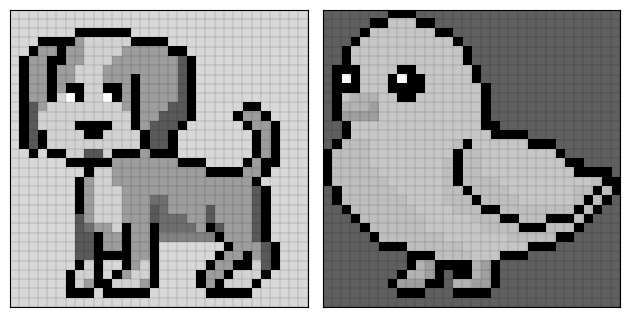

In [4]:
cat = Image.open("dog.png").convert("L")
cat_gray_array = np.array(cat)
cat_gray_norm = (cat_gray_array / 255.0) * 2 - 1
cat_vector = cat_gray_norm.flatten().reshape(1024,1)
cat_flat = cat_vector.reshape(1024)

shiba = Image.open("chick.png").convert("L")  
shiba_gray_array = np.array(shiba)
shiba_gray_norm = (shiba_gray_array / 255.0) * 2 - 1
shiba_vector = shiba_gray_norm.flatten().reshape(1024,1)
shiba_flat = shiba_vector.reshape(1024)

fig, ax = plt.subplots(1,2)

pics = [cat_gray_norm, shiba_gray_norm]

for i, pic in enumerate(pics):
    ax[i].imshow(pic, cmap='gray', vmin=-1, vmax=1)
    ax[i].set_xticks(np.arange(-0.5, pic.shape[1], 1))
    ax[i].set_yticks(np.arange(-0.5, pic.shape[0], 1))

    ax[i].grid(True, color='black', linestyle='-', linewidth=0.1)
    ax[i].tick_params(axis='both', which='both', bottom=False, top=False,
                left=False, right=False, labelbottom=False, labelleft=False)
    ax[i].set_aspect('equal')

plt.tight_layout()
plt.show()

In [4]:
def gaussian_potential(x,mu,A,sigma):
    
    N = mu.shape[1]
    V = 0

    for j in range(0,N):
        V -= A[j]*np.exp(-((np.linalg.norm(x-mu[:,j]))**2)/(2*(sigma[j]**2)))
    
    return V

def grad_gaussian_potential(x,mu,A,sigma):
    
    N = mu.shape[1]
    M = mu.shape[0]
    V = np.zeros(M)

    for j in range(0,N):
        V += (A[j]/sigma[j]**2)*(x-mu[:,j])*np.exp(-((np.linalg.norm(x-mu[:,j]))**2)/(2*(sigma[j]**2)))

    return V

mu = np.empty((1024,2))
mu[:,0] = cat_vector.reshape(1024)
mu[:,1] = shiba_vector.reshape(1024)

A = [8,11]; sigma = [10,10]

def V(x):
    return gaussian_potential(x,mu,A,sigma)

def gradV(x):
    return grad_gaussian_potential(x,mu,A,sigma)

def piZ(x):
    return np.exp(-2*V(x)/(nu**2))

def minus_gradV(x): return - gradV(x)
    
def simulate_process_EM(F,X0,T,dt,nu):

    Nt = int(T/dt)
    M = np.shape(X0)[0]
    X = np.zeros((M,Nt))
    X[:,0] = X0

    for t in range(0,Nt-1):
        X[:,t+1] = X[:,t] + dt*(F(X[:,t])) + nu*np.random.normal(0, np.sqrt(dt), size=M)
        
    return X

In [8]:
psi = 0.3
X0 = np.random.multivariate_normal(np.zeros(1024),psi*np.eye(1024)); T = 1000; dt = 0.02; nu = 0.2
time = np.linspace(0,T,int(T/dt))
x = simulate_process_EM(minus_gradV,X0,T,dt,nu)

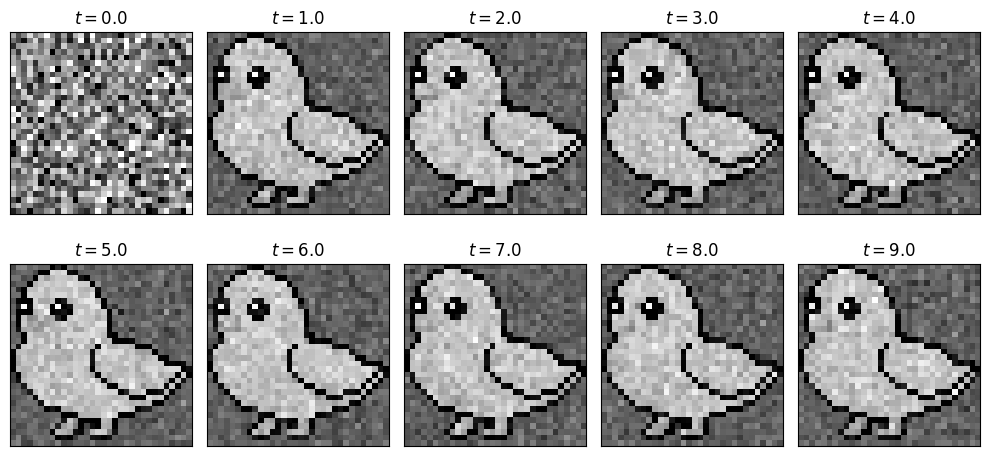

In [9]:
fig, ax = plt.subplots(2,5)
fig.set_size_inches(10,5)
for i in range(0,10):
    j = int(np.mod(i,5))
    k = int(np.floor(i/5))
    ax[k,j].imshow(x[:,i*5000].reshape(32,32), cmap='gray', vmin=-1, vmax=1)
    ax[k,j].tick_params(axis='both', which='both', bottom=False, top=False,
                left=False, right=False, labelbottom=False, labelleft=False)
    ax[k,j].set_title(r'$t='+f'{i*50*dt}$')
plt.tight_layout()
plt.show()

In [5]:
def gaussian_potential(x,mu,A,sigma):
    
    N = mu.shape[1]
    V = 0

    for j in range(0,N):
        V -= A[j]*np.exp(-((np.linalg.norm(x-mu[:,j]))**2)/(2*(sigma[j]**2)))
    
    return V

def grad_gaussian_potential(x,mu,A,sigma):
    
    N = mu.shape[1]
    M = mu.shape[0]
    V = np.zeros(M)

    for j in range(0,N):
        V += (A[j]/sigma[j])*(x-mu[:,j])*np.exp(-((np.linalg.norm(x-mu[:,j]))**2)/(2*(sigma[j]**2)))

    return V

mu = np.empty((1024,2))
mu[:,0] = cat_vector.reshape(1024)
mu[:,1] = shiba_vector.reshape(1024)

A = [7,7]; sigma = [11,11]

def V(x):
    return gaussian_potential(x,mu,A,sigma)

def gradV(x):
    return grad_gaussian_potential(x,mu,A,sigma)

def piZ(x):
    return np.exp(-2*V(x)/(nu**2))

def minus_gradV(x): return - gradV(x)
    
def simulate_process_EM(F,X0,T,dt,nu):

    Nt = int(T/dt)
    M = np.shape(X0)[0]
    X = np.zeros((M,Nt))
    X[:,0] = X0

    for t in range(0,Nt-1):
        X[:,t+1] = X[:,t] + dt*(F(X[:,t])) + nu*np.random.normal(0, np.sqrt(dt), size=M)
        
    return X

In [6]:
def find_rotation_plane(minima_1, minima_2):
    
    d = minima_2 - minima_1
    norm_d = np.linalg.norm(d)
    u = d / norm_d
    smallest_component_idx = np.argmin(np.abs(u))

    dim = len(u)
    e_k = np.zeros(dim)
    e_k[smallest_component_idx] = 1.0
    v_prime = e_k - np.dot(e_k, u) * u
    v = v_prime / np.linalg.norm(v_prime)
    
    return u, v

In [7]:
e_1, e_2 = find_rotation_plane(cat_flat,shiba_flat)

In [8]:
M = np.outer(e_2, e_1) - np.outer(e_1, e_2)

def proj_plane(a,e1,e2):
    return np.array([np.dot(a,e1),np.dot(a,e2)])

alpha = 1

def R(x):
    return alpha*M@gradV(x)

def f(x):
    return -gradV(x) + R(x)

In [9]:
nu = 0.3

def piZ(x):
    return np.exp(-2*V(x)/(nu**2))

xmin = -25; xmax = 25
ymin = -25; ymax = 25

x1 = np.linspace(xmin, xmax, 200)
y1 = np.linspace(ymin, ymax, 200)
X, Y = np.meshgrid(x1, y1)

xc = np.linspace(xmin, xmax, 20)
yc = np.linspace(ymin, ymax, 20)
Xc, Yc = np.meshgrid(xc, yc)

Z = np.zeros_like(X)
for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        x = X[i, j]*e_1 + Y[i, j]*e_2
        Z[i, j] = V(x)

U, U_R, U_gradR = np.zeros_like(Xc), np.zeros_like(Xc), np.zeros_like(Xc)
V_, V_R, V_gradR = np.zeros_like(Xc), np.zeros_like(Xc), np.zeros_like(Xc)
Unorm, URnorm, UgradRnorm = np.zeros_like(Xc), np.zeros_like(Xc), np.zeros_like(Xc)
Vnorm, VRnorm, VgradRnorm = np.zeros_like(Xc), np.zeros_like(Xc), np.zeros_like(Xc)
magnitude, Rmagnitude, gradRmagnitude = np.zeros_like(Xc), np.zeros_like(Xc), np.zeros_like(Xc)

for i in range(Xc.shape[0]):
    for j in range(Xc.shape[1]):
        x = Xc[i, j]*e_1 + Yc[i, j]*e_2  
        
        grad = gradV(x)
        grad_ld = proj_plane(grad,e_1,e_2)

        R_ = R(x)
        R_ld = proj_plane(R_,e_1,e_2)

        U[i, j] = -grad_ld[0]
        V_[i, j] = -grad_ld[1]
        magnitude[i, j] = np.linalg.norm(grad_ld) + 1e-11
        Unorm[i, j] = U[i, j] / magnitude[i, j]
        Vnorm[i, j] = V_[i, j] / magnitude[i, j]
        
        U_R[i, j] = R_ld[0]
        V_R[i, j] = R_ld[1]
        Rmagnitude[i, j] = np.linalg.norm(R_ld) + 1e-11
        URnorm[i, j] = U_R[i, j] / Rmagnitude[i, j]
        VRnorm[i, j] = V_R[i, j] / Rmagnitude[i, j]

        U_gradR[i, j] = -grad_ld[0] + R_ld[0]
        V_gradR[i, j] = -grad_ld[1] + R_ld[1]
        gradRmagnitude[i, j] = np.linalg.norm(-grad_ld + R_ld) + 1e-11
        UgradRnorm[i, j] = U_gradR[i, j] / gradRmagnitude[i, j]
        VgradRnorm[i, j] = V_gradR[i, j] / gradRmagnitude[i, j]

Text(0.5, 1.0, '$-\\nabla V + R$')

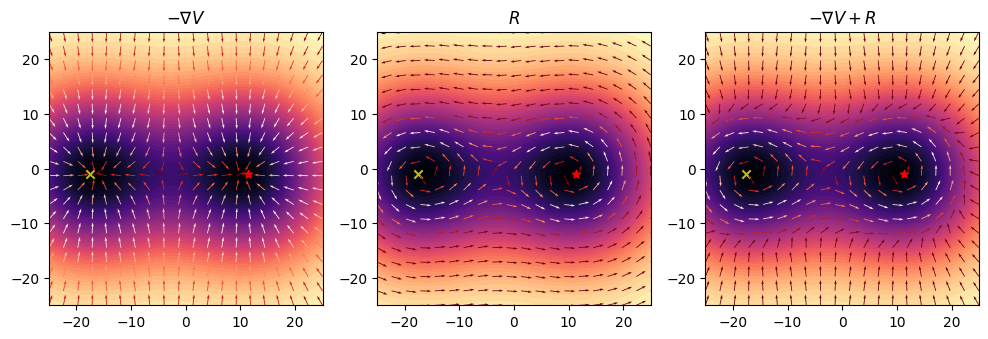

In [38]:
fig, ax = plt.subplots(1,3)
fig.set_size_inches(12,4)

cat_ld, shiba_ld = proj_plane(cat_flat, e_1,e_2), proj_plane(shiba_flat, e_1,e_2)

for a in ax:
    c = a.contourf(X, Y, Z, levels=50, cmap='magma')
    c.set_edgecolor('face')
    a.scatter(cat_ld[0],cat_ld[1],marker ='x', color = 'y') # cat
    a.scatter(shiba_ld[0],shiba_ld[1],marker ='*', color = 'r') # shiba
    a.set_aspect('equal')

ax[0].quiver(Xc, Yc, Unorm, Vnorm, magnitude, cmap = 'Reds_r',scale = 25)
ax[0].set_title(r'$-\nabla V$')

ax[1].quiver(Xc, Yc, URnorm, VRnorm, Rmagnitude, cmap = 'Reds_r',scale = 25)
ax[1].set_title(r'$R$')

ax[2].quiver(Xc, Yc, UgradRnorm, VgradRnorm, gradRmagnitude, cmap = 'Reds_r',scale = 25)
ax[2].set_title(r'$-\nabla V + R$')

In [12]:
xi = 0.5
level_set = -3.2

def g(p):
    return np.exp(-((V(p)-level_set)**2)/(2*xi**2))

gZ = np.zeros_like(X)

for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        x = X[i, j]*e_1 + Y[i, j]*e_2
        gZ[i, j] = g(x)

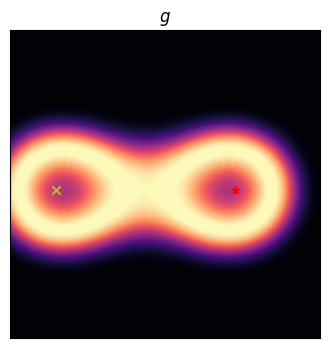

In [39]:
fig, ax = plt.subplots(1,1)
fig.set_size_inches(4,4)

c = ax.contourf(X, Y, gZ, levels=50, cmap='magma')
c.set_edgecolor('face')
ax.scatter(cat_ld[0],cat_ld[1],marker ='x', color = 'y') # cat
ax.scatter(shiba_ld[0],shiba_ld[1],marker ='*', color = 'r') # shiba
ax.set_title(r'$g$')
ax.set_xticks([])
ax.set_yticks([])

In [14]:
alpha = 40

def R(x):
    return alpha*M@gradV(x)*g(x)
def f(x):
    return -gradV(x) + R(x)

In [15]:
nu = 0.4

def piZ(x):
    return np.exp(-2*V(x)/(nu**2))

xmin = -25; xmax = 25
ymin = -25; ymax = 25

x1 = np.linspace(xmin, xmax, 200)
y1 = np.linspace(ymin, ymax, 200)
X, Y = np.meshgrid(x1, y1)

xc = np.linspace(xmin, xmax, 20)
yc = np.linspace(ymin, ymax, 20)
Xc, Yc = np.meshgrid(xc, yc)

Z = np.zeros_like(X)
for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        x = X[i, j]*e_1 + Y[i, j]*e_2
        Z[i, j] = V(x)

U, U_R, U_gradR = np.zeros_like(Xc), np.zeros_like(Xc), np.zeros_like(Xc)
V_, V_R, V_gradR = np.zeros_like(Xc), np.zeros_like(Xc), np.zeros_like(Xc)
Unorm, URnorm, UgradRnorm = np.zeros_like(Xc), np.zeros_like(Xc), np.zeros_like(Xc)
Vnorm, VRnorm, VgradRnorm = np.zeros_like(Xc), np.zeros_like(Xc), np.zeros_like(Xc)
magnitude, Rmagnitude, gradRmagnitude = np.zeros_like(Xc), np.zeros_like(Xc), np.zeros_like(Xc)

for i in range(Xc.shape[0]):
    for j in range(Xc.shape[1]):
        x = Xc[i, j]*e_1 + Yc[i, j]*e_2  
        
        grad = gradV(x)
        grad_ld = proj_plane(grad,e_1,e_2)

        R_ = R(x)
        R_ld = proj_plane(R_,e_1,e_2)

        U[i, j] = -grad_ld[0]
        V_[i, j] = -grad_ld[1]
        magnitude[i, j] = np.linalg.norm(grad_ld) + 1e-11
        Unorm[i, j] = U[i, j] / magnitude[i, j]
        Vnorm[i, j] = V_[i, j] / magnitude[i, j]
        
        U_R[i, j] = R_ld[0]
        V_R[i, j] = R_ld[1]
        Rmagnitude[i, j] = np.linalg.norm(R_ld) + 1e-11
        URnorm[i, j] = U_R[i, j] / Rmagnitude[i, j]
        VRnorm[i, j] = V_R[i, j] / Rmagnitude[i, j]

        U_gradR[i, j] = -grad_ld[0] + R_ld[0]
        V_gradR[i, j] = -grad_ld[1] + R_ld[1]
        gradRmagnitude[i, j] = np.linalg.norm(-grad_ld + R_ld) + 1e-11
        UgradRnorm[i, j] = U_gradR[i, j] / gradRmagnitude[i, j]
        VgradRnorm[i, j] = V_gradR[i, j] / gradRmagnitude[i, j]

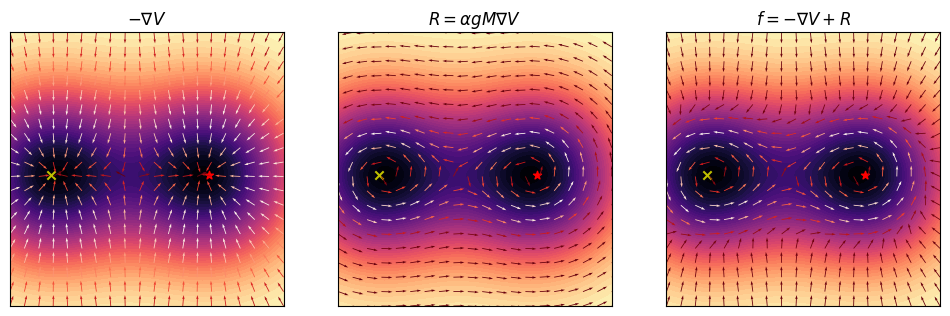

In [21]:
fig, ax = plt.subplots(1,3)
fig.set_size_inches(12,4)

cat_ld, shiba_ld = proj_plane(cat_flat, e_1,e_2), proj_plane(shiba_flat, e_1,e_2)

for a in ax:
    a.contourf(X, Y, Z, levels=50, cmap='magma')
    a.scatter(cat_ld[0],cat_ld[1],marker ='x', color = 'y') # cat
    a.scatter(shiba_ld[0],shiba_ld[1],marker ='*', color = 'r') # shiba
    a.set_aspect('equal')
    a.set_xticks([])
    a.set_yticks([])

ax[0].quiver(Xc, Yc, Unorm, Vnorm, magnitude, cmap = 'Reds_r',scale = 25)
ax[0].set_title(r'$-\nabla V$')

ax[1].quiver(Xc, Yc, URnorm, VRnorm, Rmagnitude, cmap = 'Reds_r',scale = 25)
ax[1].set_title(r'$R = \alpha gM\nabla V$')

ax[2].quiver(Xc, Yc, UgradRnorm, VgradRnorm, gradRmagnitude, cmap = 'Reds_r',scale = 25)
ax[2].set_title(r'$f = -\nabla V + R$')


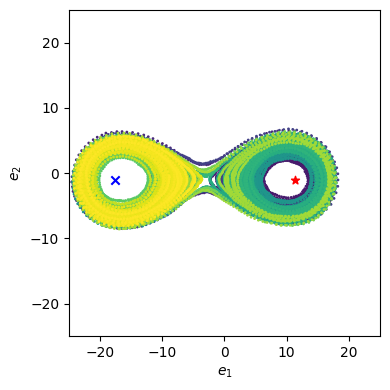

In [26]:
psi = 0.1
X0 = np.random.multivariate_normal(np.zeros(1024),psi*np.eye(1024)); T = 1000; dt = 0.02; nu = 0.315
time = np.linspace(0,T,int(T/dt))
x = simulate_process_EM(f,X0,T,dt,nu)

fig, ax = plt.subplots(1,1)
fig.set_size_inches(4,4)

x_ld = np.empty((2,x.shape[1]))

for t in range(0,x.shape[1]):
    x_ld[:,t] = proj_plane(x[:,t],e_1,e_2)


ax.scatter(x_ld[0,:],x_ld[1,:],c=time[:],cmap='viridis',s=1)
ax.scatter(cat_ld[0],cat_ld[1],marker ='x', color = 'b') # cat
ax.scatter(shiba_ld[0],shiba_ld[1],marker ='*', color = 'r') # shiba

ax.set_xlabel(r'$e_1$')
ax.set_ylabel(r'$e_2$')
ax.set_xlim(xmin,xmax)
ax.set_ylim(ymin,ymax)

plt.tight_layout()
plt.show()

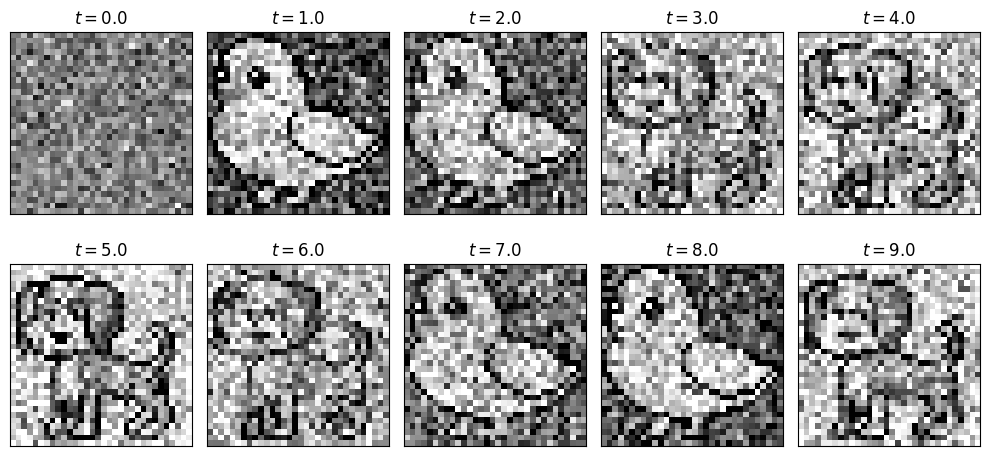

In [35]:
fig, ax = plt.subplots(2,5)
fig.set_size_inches(10,5)
for i in range(0,10):
    j = int(np.mod(i,5))
    k = int(np.floor(i/5))
    ax[k,j].imshow(x[:,i*4000].reshape(32,32), cmap='grey', vmin=-1, vmax=1)
    ax[k,j].tick_params(axis='both', which='both', bottom=False, top=False,
                left=False, right=False, labelbottom=False, labelleft=False)
    ax[k,j].set_title(r'$t='+f'{i*50*dt}$')
plt.tight_layout()
plt.show()